In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

df = pd.read_csv("../data/raw/fraud_oracle.csv")

X = df.drop(columns=[
    "FraudFound_P",
    "PolicyNumber",
    "RepNumber"
])

y = df["FraudFound_P"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train = X_train.copy()
X_test = X_test.copy()

# Remembers which ages were unknown before filling them.
X_train["AgeMissing"] = X_train["Age"].eq(0).astype(str)
X_test["AgeMissing"] = X_test["Age"].eq(0).astype(str)

# Zero is treated as a missing age.
X_train["Age"] = X_train["Age"].replace(0, np.nan)
X_test["Age"] = X_test["Age"].replace(0, np.nan)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (12336, 31)
Testing: (3084, 31)


In [20]:
# Scales numeric inputs so larger values do not dominate training.
# One-hot encode categories without giving them an artificial order.
# Uses dense arrays for the neural network.
# Each training fold will fit its own preprocessing.

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features += ["Year", "DriverRating"]

numerical_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in categorical_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("MLP preprocessing ready")

MLP preprocessing ready


In [21]:
# Gives fraud records more weight because they are less common.
# These weights are for fitting on the full training set.
# Cross-validation calculates separate weights inside each fold.

from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Non-fraud weight:", sample_weights[y_train == 0][0])
print("Fraud weight:", sample_weights[y_train == 1][0])

Non-fraud weight: 0.5318158303155717
Fraud weight: 8.357723577235772


In [22]:
# Starts with two hidden layers containing 64 and 32 neurons.
# ReLU and Adam are practical starting choices for this experiment.
# Alpha controls weight regularisation to discourage overfitting.
# These are baseline settings, not proven optimal values.
# The training report below does not measure unseen-data performance.

mlp_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=300,
        random_state=42
    ))
])

mlp_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

mlp_train_pred = mlp_model.predict(X_train)

print("MLP — Training Results")
print(classification_report(
    y_train,
    mlp_train_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, mlp_train_pred))

MLP — Training Results
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     11598
           1       1.00      1.00      1.00       738

    accuracy                           1.00     12336
   macro avg       1.00      1.00      1.00     12336
weighted avg       1.00      1.00      1.00     12336


Confusion Matrix:
[[11598     0]
 [    0   738]]


In [23]:
# Try a smaller network with 32 and 16 neurons.
# Increases alpha from 0.001 to 0.01 for stronger regularisation.
# This tests an alternative setup that may reduce overfitting.
# Several settings change together, so we cannot isolate one cause.

regularized_mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=200,
        random_state=42
    ))
])

print("Regularized MLP created successfully")

Regularized MLP created successfully


Original MLP: finished fold 1/5
Original MLP: finished fold 2/5
Original MLP: finished fold 3/5
Original MLP: finished fold 4/5
Original MLP: finished fold 5/5


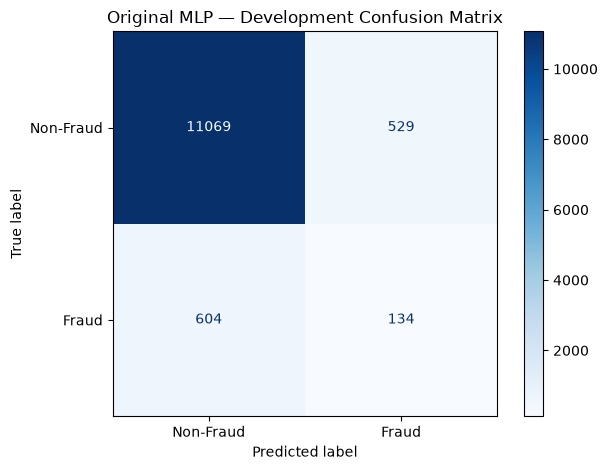

Regularized MLP: finished fold 1/5
Regularized MLP: finished fold 2/5
Regularized MLP: finished fold 3/5
Regularized MLP: finished fold 4/5
Regularized MLP: finished fold 5/5


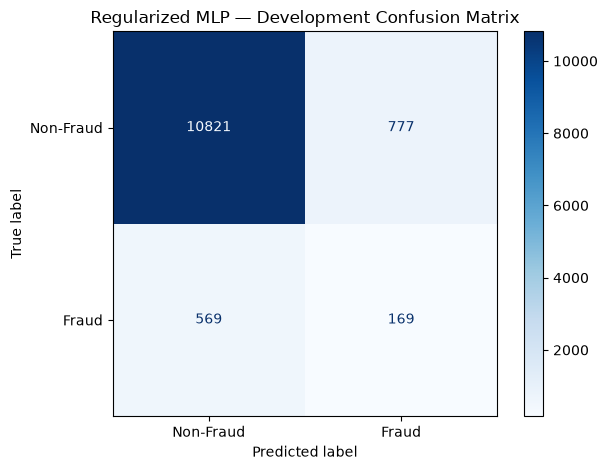


Mean development cross-validation scores:


,Precision,Recall,F1,Average Precision
Model,,,,
Original MLP,0.2025,0.1815,0.1911,0.1724
Regularized MLP,0.1779,0.2292,0.1967,0.1752


In [24]:
# Evaluates on records excluded from each fold's training.
# Fits preprocessing and calculate class weights inside each fold.
# Reports fraud precision, recall, F1 and average precision.

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Original MLP": mlp_model,
    "Regularized MLP": regularized_mlp
}

fold_results = []

for name, model in models.items():
    # Store a validation prediction for every training record.
    oof_predictions = np.zeros(len(y_train), dtype=int)

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train), start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Calculate weights using only this fold's training labels.
        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        # Fit a fresh model and preprocessor for each fold.
        fold_model = clone(model)
        fold_model.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        predictions = fold_model.predict(X_fold_val)
        probabilities = fold_model.predict_proba(X_fold_val)[:, 1]
        oof_predictions[val_idx] = predictions

        fold_results.append({
            "Model": name,
            "Fold": fold,
            "Precision": precision_score(
                y_fold_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_fold_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_fold_val, predictions, zero_division=0
            ),
            "Average Precision": average_precision_score(
                y_fold_val, probabilities
            )
        })

        print(f"{name}: finished fold {fold}/5")

    # These predictions were made on records unseen during each fit.
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        oof_predictions,
        display_labels=["Non-Fraud", "Fraud"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(name + " — Development Confusion Matrix")
    plt.tight_layout()
    plt.show()

mlp_fold_results = pd.DataFrame(fold_results)

mlp_comparison = (
    mlp_fold_results
    .groupby("Model", sort=False)[
        ["Precision", "Recall", "F1", "Average Precision"]
    ]
    .mean()
)

print("\nMean development cross-validation scores:")
display(mlp_comparison.round(4))

In [25]:
from pathlib import Path

# Save the current scores so other notebooks can read them.
results_dir = Path("../results/tabular")
results_dir.mkdir(parents=True, exist_ok=True)

mlp_comparison.to_csv(
    results_dir / "mlp_cv_comparison.csv",
    index_label="Model"
)

# Keep the individual fold scores for checking variation.
mlp_fold_results.to_csv(
    results_dir / "mlp_cv_folds.csv",
    index=False
)

print("MLP cross-validation results saved.")

MLP cross-validation results saved.
